# Synthetic income population — sanity check

Loads `data/processed/synthetic_income_paths.parquet` (produced by `src/simulation/income_paths.py`)
and checks that the simulated population behaves as intended: cohort weights match PLFS shares,
sample paths per volatility tier look qualitatively right, and contribution-skip behavior is
concentrated where the paper's claim says it should be (informal, volatile-income cohorts).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/processed/synthetic_income_paths.parquet")
calibration = pd.read_csv("../data/processed/plfs_calibration.csv")
df.head()

,subscriber_id,employment_type,sector,volatility_tier,month_index,income,is_disruption_month,contribution
0,10,casual_labour,agriculture,medium,0,25063.014123,False,1605.041130
1,10,casual_labour,agriculture,medium,1,10497.172962,False,439.773837
2,10,casual_labour,agriculture,medium,2,7768.450041,True,221.476003
3,10,casual_labour,agriculture,medium,3,9786.211342,False,382.896907
4,10,casual_labour,agriculture,medium,4,9310.855373,False,344.868430


## Cohort weights: simulated vs. PLFS-calibrated population share

In [2]:
n_subscribers = df["subscriber_id"].nunique()
sim_share = (
    df.drop_duplicates("subscriber_id")["employment_type"].value_counts(normalize=True) * 100
)
compare = calibration.set_index("employment_type")[["population_share_pct"]].copy()
compare["simulated_share_pct"] = sim_share
compare

,population_share_pct,simulated_share_pct
employment_type,,
regular_salaried,21.7,22.35
casual_labour,19.8,18.80
self_employed,58.4,58.85


## Sample income paths, one per employment type

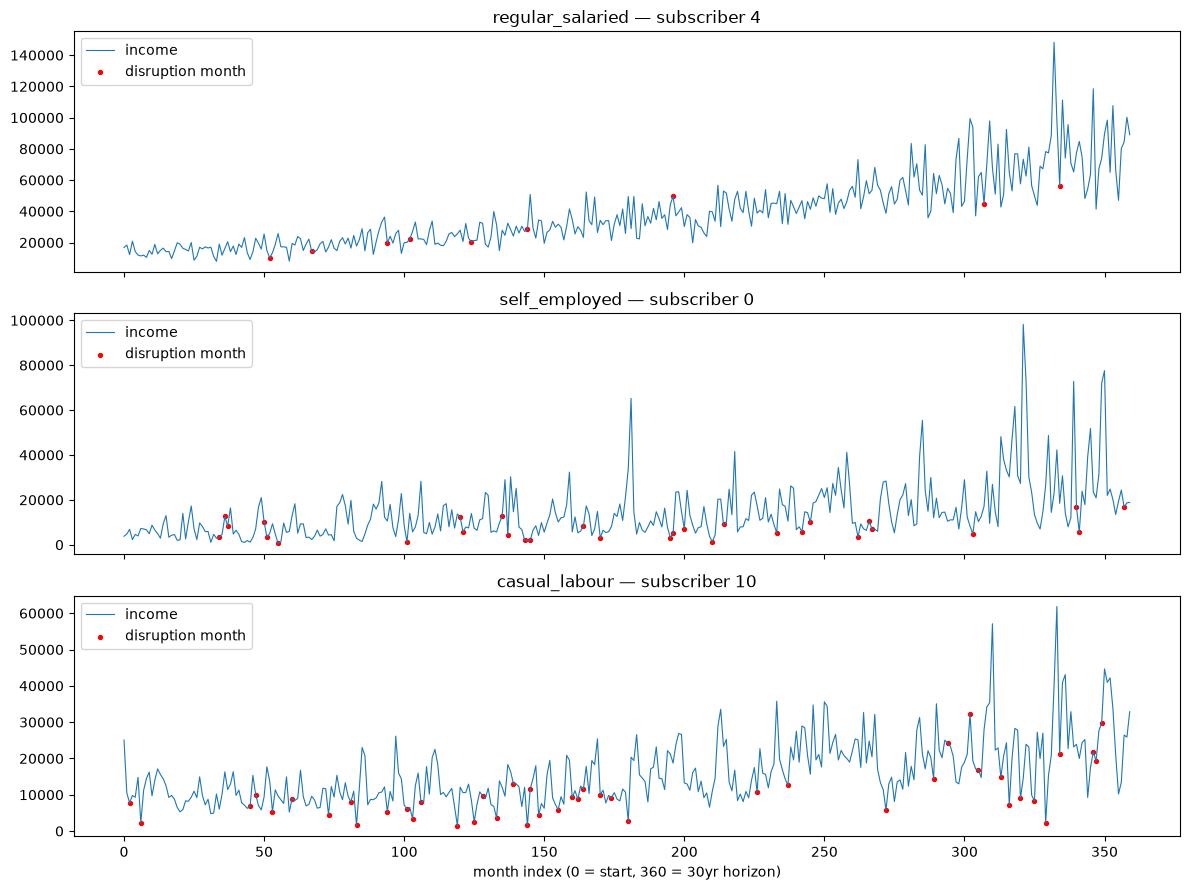

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, employment_type in zip(axes, ["regular_salaried", "self_employed", "casual_labour"]):
    sub = df[df.employment_type == employment_type]
    sample_id = sub["subscriber_id"].iloc[0]
    path = sub[sub.subscriber_id == sample_id].sort_values("month_index")
    ax.plot(path["month_index"], path["income"], linewidth=0.8, label="income")
    disrupted = path[path["is_disruption_month"]]
    ax.scatter(disrupted["month_index"], disrupted["income"], color="red", s=8, label="disruption month")
    ax.set_title(f"{employment_type} — subscriber {sample_id}")
    ax.legend(loc="upper left")
axes[-1].set_xlabel("month index (0 = start, 360 = 30yr horizon)")
plt.tight_layout()
plt.show()

## Contribution over the same sample paths

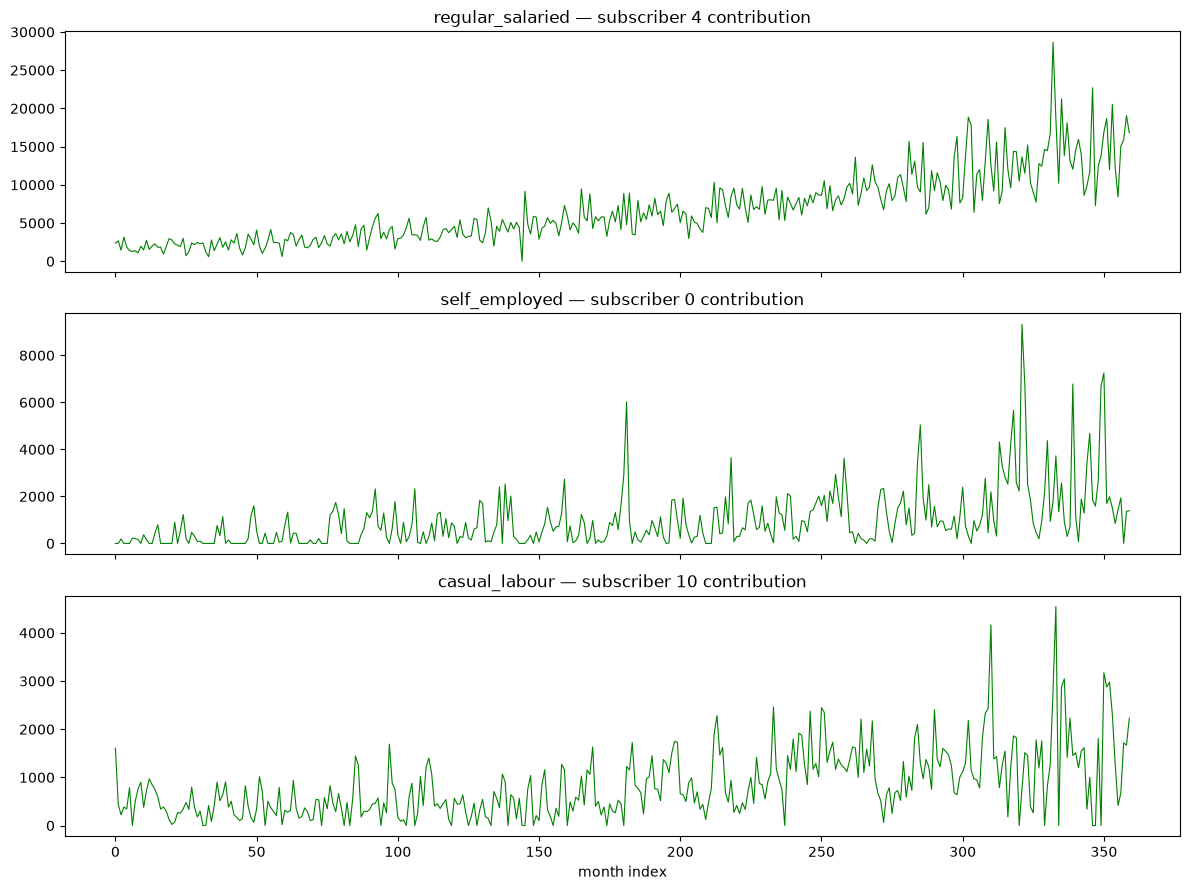

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, employment_type in zip(axes, ["regular_salaried", "self_employed", "casual_labour"]):
    sub = df[df.employment_type == employment_type]
    sample_id = sub["subscriber_id"].iloc[0]
    path = sub[sub.subscriber_id == sample_id].sort_values("month_index")
    ax.plot(path["month_index"], path["contribution"], linewidth=0.8, color="green")
    ax.set_title(f"{employment_type} — subscriber {sample_id} contribution")
axes[-1].set_xlabel("month index")
plt.tight_layout()
plt.show()

## Skip-rate summary (core claim check)

The paper's claim is that informal-sector cohorts have irregular contribution capacity. This should
show up here as a much higher zero-contribution-month rate for `self_employed`/`casual_labour` than
`regular_salaried`.

In [5]:
summary = df.groupby("employment_type").agg(
    pct_zero_contribution_months=("contribution", lambda s: (s == 0).mean() * 100),
    mean_income=("income", "mean"),
    simulated_income_cv=("income", lambda s: s.std() / s.mean()),
)
summary

,pct_zero_contribution_months,mean_income,simulated_income_cv
employment_type,,,
casual_labour,10.714391,19650.122629,0.753906
regular_salaried,0.072707,57469.703666,0.636607
self_employed,11.221797,36833.681643,1.432577


## Distribution of each subscriber's own skip rate

Not just the pooled average — the spread across subscribers within a cohort, since the paper's claim
is about individual irregularity, not just a cohort-level average.

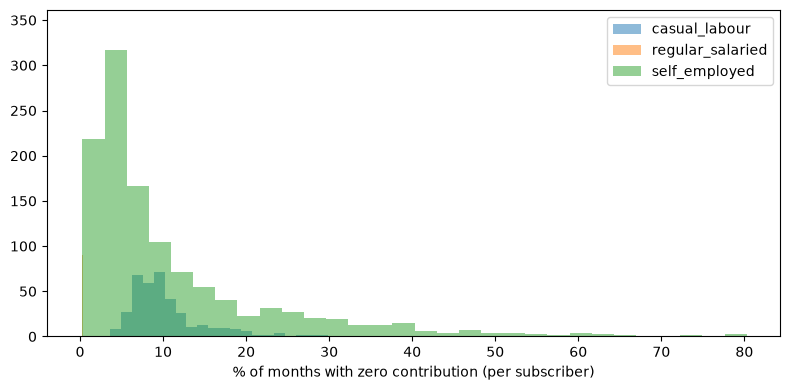

In [6]:
per_subscriber_skip = (
    df.groupby(["subscriber_id", "employment_type"])["contribution"]
    .apply(lambda s: (s == 0).mean() * 100)
    .reset_index(name="pct_zero_months")
)
fig, ax = plt.subplots(figsize=(8, 4))
for employment_type, g in per_subscriber_skip.groupby("employment_type"):
    ax.hist(g["pct_zero_months"], bins=30, alpha=0.5, label=employment_type)
ax.set_xlabel("% of months with zero contribution (per subscriber)")
ax.legend()
plt.tight_layout()
plt.show()